# 10_02 Sensitivity Completeness Analysis

Notebook ligero para analizar la variante `central_band_dropout_noise` sin depender del notebook anterior.

| violation_strength | DFPV | KPV | PMMR | Weighted DFPV | Weighted KPV | Weighted PMMR |
|---:|---:|---:|---:|---:|---:|---:|
| 0.00 | 6.1234 ± 0.4054 | 3.9841 ± 0.1299 | 6.8165 ± 0.3540 | 5.4861 ± 0.3747 | 3.9383 ± 0.1485 | 6.6935 ± 0.3701 |
| 0.25 | 6.5036 ± 0.9322 | 4.1522 ± 0.0997 | 6.7700 ± 0.3871 | 5.1148 ± 0.8426 | 4.0738 ± 0.1010 | 6.6424 ± 0.4071 |
| 0.50 | 6.6456 ± 0.8590 | 4.2766 ± 0.1651 | 6.9224 ± 0.4750 | 6.4270 ± 0.4353 | 4.3244 ± 0.1675 | 6.6186 ± 0.4778 |
| 0.75 | 6.7945 ± 1.0576 | 4.4260 ± 0.0652 | 7.3966 ± 0.7218 | 6.2594 ± 1.0628 | 4.4413 ± 0.1612 | 7.1814 ± 0.7435 |
| 0.90 | 6.4817 ± 0.8561 | 4.5014 ± 0.1528 | 7.3243 ± 0.5580 | 6.0563 ± 0.4708 | 4.5651 ± 0.1963 | 7.0648 ± 0.6701 |

In [11]:
from pathlib import Path
import csv
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
# Match the paper figures in 07_02: white canvas and serif text.
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'font.size': 10.5,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'text.color': 'black',
    'axes.labelcolor': 'black',
    'axes.edgecolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'legend.labelcolor': 'black',
})


In [12]:
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
RESULTS_DIR = PROJECT_ROOT / 'results' / 'sensitivity_completeness_10_02'
DIAGNOSTICS_DIR = PROJECT_ROOT / 'results' / 'completeness_10_02_diagnostics'
METRICS_CSV = RESULTS_DIR / 'results_metrics.csv'
DIAGNOSTICS_CSV = DIAGNOSTICS_DIR / 'completeness_10_02_latent_diagnostics.csv'
RESULTS_DIR, DIAGNOSTICS_DIR

(WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/sensitivity_completeness_10_02'),
 WindowsPath('C:/Users/Alex/CODE/optimal_treatment_proximal_inference/weighted_proximal_oosr/results/completeness_10_02_diagnostics'))

In [13]:
def read_rows(path: Path):
    with path.open(encoding='utf-8', newline='') as handle:
        return list(csv.DictReader(handle))

def summarize(rows, x_key, y_key, filters=None, *, n_boot=3000, confidence=0.95, seed=13):
    grouped = defaultdict(list)
    for row in rows:
        if filters and any(str(row.get(k)) != str(v) for k, v in filters.items()):
            continue
        if x_key not in row or y_key not in row or row[y_key] in ('', None):
            continue
        x, value = float(row[x_key]), float(row[y_key])
        if np.isfinite(x) and np.isfinite(value):
            grouped[x].append(value)
    xs = np.array(sorted(grouped.keys()), dtype=float)
    means, ci_low, ci_high = [], [], []
    rng = np.random.default_rng(seed)
    alpha = (1.0 - confidence) / 2.0
    for x in xs:
        values = np.asarray(grouped[x], dtype=float)
        means.append(float(np.mean(values)))
        if len(values) < 2:
            ci_low.append(np.nan)
            ci_high.append(np.nan)
            continue
        samples = rng.choice(values, size=(n_boot, len(values)), replace=True)
        low, high = np.quantile(samples.mean(axis=1), [alpha, 1.0 - alpha])
        ci_low.append(float(low))
        ci_high.append(float(high))
    return xs, np.asarray(means), np.asarray(ci_low), np.asarray(ci_high)

metrics_rows = read_rows(METRICS_CSV)
diagnostic_rows = read_rows(DIAGNOSTICS_CSV)
len(metrics_rows), len(diagnostic_rows)

(500, 100)

In [14]:
sorted({row['method'] for row in metrics_rows if row.get('split') == 'test'})


['DFPV', 'KPV', 'PMMR', 'Weighted DFPV', 'Weighted KPV', 'Weighted PMMR']

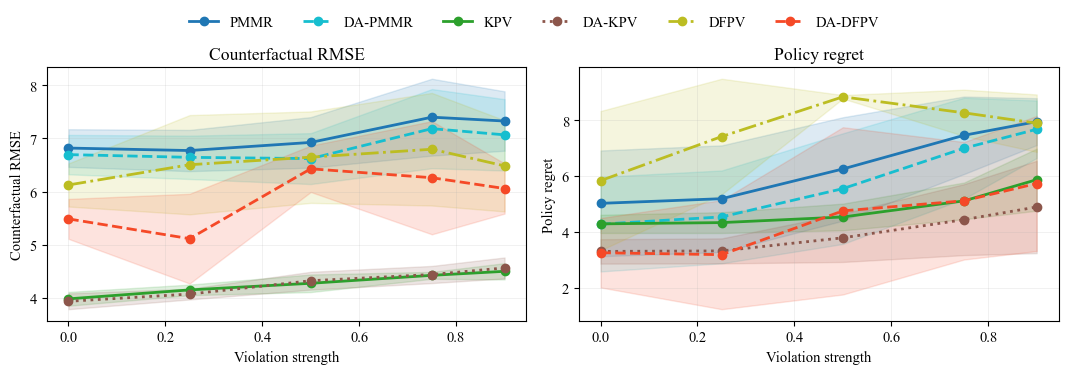

In [24]:
# Match the method palette, line styles, and labels used in 07_02.
METHOD_ORDER = ['PMMR', 'Weighted PMMR', 'KPV', 'Weighted KPV', 'DFPV', 'Weighted DFPV']
METHOD_COLORS = {
    'PMMR': '#1f77b4', 'Weighted PMMR': '#17becf',
    'KPV': '#2ca02c', 'Weighted KPV': '#8c564b',
    'DFPV': '#bcbd22', 'Weighted DFPV': '#F54927',
}
METHOD_LINESTYLES = {
    'PMMR': '-', 'Weighted PMMR': '--',
    'KPV': '-', 'Weighted KPV': ':',
    'DFPV': '-.', 'Weighted DFPV': '--',
}
METHOD_LABELS = {
    'Weighted PMMR': 'DA-PMMR',
    'Weighted KPV': 'DA-KPV',
    'Weighted DFPV': 'DA-DFPV',
}

metric_specs = [
    ('global_rmse', 'Counterfactual RMSE'),
    ('regret', 'Policy regret'),
]
available_methods = {row['method'] for row in metrics_rows if row.get('split') == 'test'}
methods = [method for method in METHOD_ORDER if method in available_methods]
methods += sorted(available_methods - set(methods))

fig, axes = plt.subplots(1, len(metric_specs), figsize=(10.8, 4.2))
for ax, (metric_key, title) in zip(axes, metric_specs):
    for method in methods:
        xs, means, ci_low, ci_high = summarize(
            metrics_rows,
            'completeness_violation_strength',
            metric_key,
            filters={'split': 'test', 'method': method},
        )
        if xs.size == 0:
            continue
        color = METHOD_COLORS.get(method, 'tab:blue')
        ax.plot(xs, means, marker='o', linewidth=2, color=color,
                linestyle=METHOD_LINESTYLES.get(method, '-'),
                label=METHOD_LABELS.get(method, method))
        ax.fill_between(xs, ci_low, ci_high, color=color, alpha=0.15)
    ax.set_title(title)
    ax.set_xlabel('Violation strength')
    ax.set_ylabel(title)
    ax.grid(alpha=0.25)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.9),
           ncol=min(len(labels), 6), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.83))
plt.savefig(RESULTS_DIR / 'completeness_metrics.png')
plt.show()


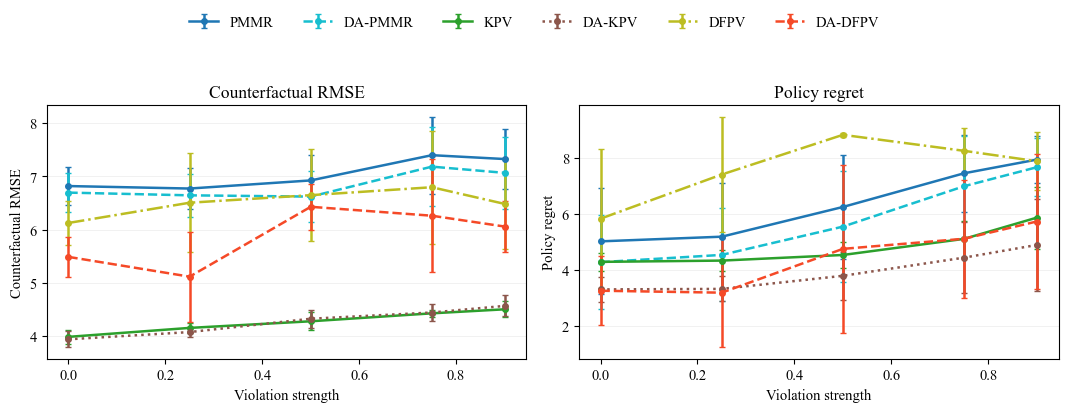

In [16]:
# Compact two-panel view of the global test metrics, with one legend for both panels.
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.2), sharex=True)
for ax, (metric_key, ylabel) in zip(axes, metric_specs):
    for method in methods:
        xs, means, ci_low, ci_high = summarize(
            metrics_rows, 'completeness_violation_strength', metric_key,
            filters={'split': 'test', 'method': method},
        )
        if not xs.size:
            continue
        color = METHOD_COLORS.get(method, 'tab:blue')
        ax.plot(xs, means, marker='o', markersize=4, linewidth=1.8, color=color,
                linestyle=METHOD_LINESTYLES.get(method, '-'),
                label=METHOD_LABELS.get(method, method))
        ax.vlines(xs, ci_low, ci_high, color=color, linewidth=1.0)
        ax.plot(xs, ci_low, linestyle='none', marker='_', color=color, markersize=5)
        ax.plot(xs, ci_high, linestyle='none', marker='_', color=color, markersize=5)
    ax.set_title(ylabel)
    ax.set_xlabel('Violation strength')
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.25)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.99),
           ncol=min(len(labels), 6), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.83))
plt.show()


In [17]:
# Summary of mean and percentile bootstrap confidence intervals.
import pandas as pd

records = []
for method in methods:
    for metric_key, metric_label in metric_specs:
        xs, means, ci_low, ci_high = summarize(
            metrics_rows,
            'completeness_violation_strength',
            metric_key,
            filters={'split': 'test', 'method': method},
        )
        for x, mean, low, high in zip(xs, means, ci_low, ci_high):
            records.append({
                'violation_strength': x,
                'method': method,
                'metric': metric_label,
                'mean [95% CI]': f"{mean:.4f} [{low:.4f}, {high:.4f}]",
            })

df = pd.DataFrame(records)
table = df.pivot_table(
    index='violation_strength',
    columns=['method', 'metric'],
    values='mean [95% CI]',
    aggfunc='first',
)
table.to_csv('completeness_metrics_summary.csv')
table


method                            DFPV                                  KPV  \
metric             Counterfactual RMSE    Policy regret Counterfactual RMSE   
violation_strength                                                            
0.00                   6.1234 ± 0.4054  5.8325 ± 2.4916     3.9841 ± 0.1299   
0.25                   6.5036 ± 0.9322  7.4121 ± 2.0674     4.1522 ± 0.0997   
0.50                   6.6456 ± 0.8590  8.8325 ± 0.0626     4.2766 ± 0.1651   
0.75                   6.7945 ± 1.0576  8.2602 ± 0.8284     4.4260 ± 0.0652   
0.90                   6.4817 ± 0.8561  7.8892 ± 1.0276     4.5014 ± 0.1528   

method                                             PMMR                   \
metric                Policy regret Counterfactual RMSE    Policy regret   
violation_strength                                                         
0.00                4.2859 ± 0.3252     6.8165 ± 0.3540  5.0202 ± 1.8922   
0.25                4.3313 ± 0.3719     6.7700 ± 0.3871  5.1869 ± 1.9077   
0.50                4.5324 ± 0.4774     6.9224 ± 0.4750  6.2504 ± 1.8512   
0.75                5.1085 ± 0.6557     7.3966 ± 0.7218  7.4560 ± 1.3872   
0.90                5.8675 ± 1.1111     7.3243 ± 0.5580  7.9446 ± 0.8382   

method                   Weighted DFPV                         Weighted KPV  \
metric             Counterfactual RMSE    Policy regret Counterfactual RMSE   
violation_strength                                                            
0.00                   5.4861 ± 0.3747  3.2526 ± 1.2414     3.9383 ± 0.1485   
0.25                   5.1148 ± 0.8426  3.1837 ± 1.9519     4.0738 ± 0.1010   
0.50                   6.4270 ± 0.4353  4.7510 ± 2.9932     4.3244 ± 0.1675   
0.75                   6.2594 ± 1.0628  5.1126 ± 2.1028     4.4413 ± 0.1612   
0.90                   6.0563 ± 0.4708  5.7305 ± 2.4164     4.5651 ± 0.1963   

method                                    Weighted PMMR                   
metric                Policy regret Counterfactual RMSE    Policy regret  
violation_strength                                                        
0.00                3.2997 ± 0.4368     6.6935 ± 0.3701  4.2751 ± 1.6932  
0.25                3.3181 ± 0.4479     6.6424 ± 0.4071  4.5353 ± 1.6612  
0.50                3.7869 ± 0.8647     6.6186 ± 0.4778  5.5469 ± 1.9802  
0.75                4.4369 ± 1.2699     7.1814 ± 0.7435  6.9926 ± 1.8082  
0.90                4.8901 ± 1.6535     7.0648 ± 0.6701  7.6718 ± 1.0295

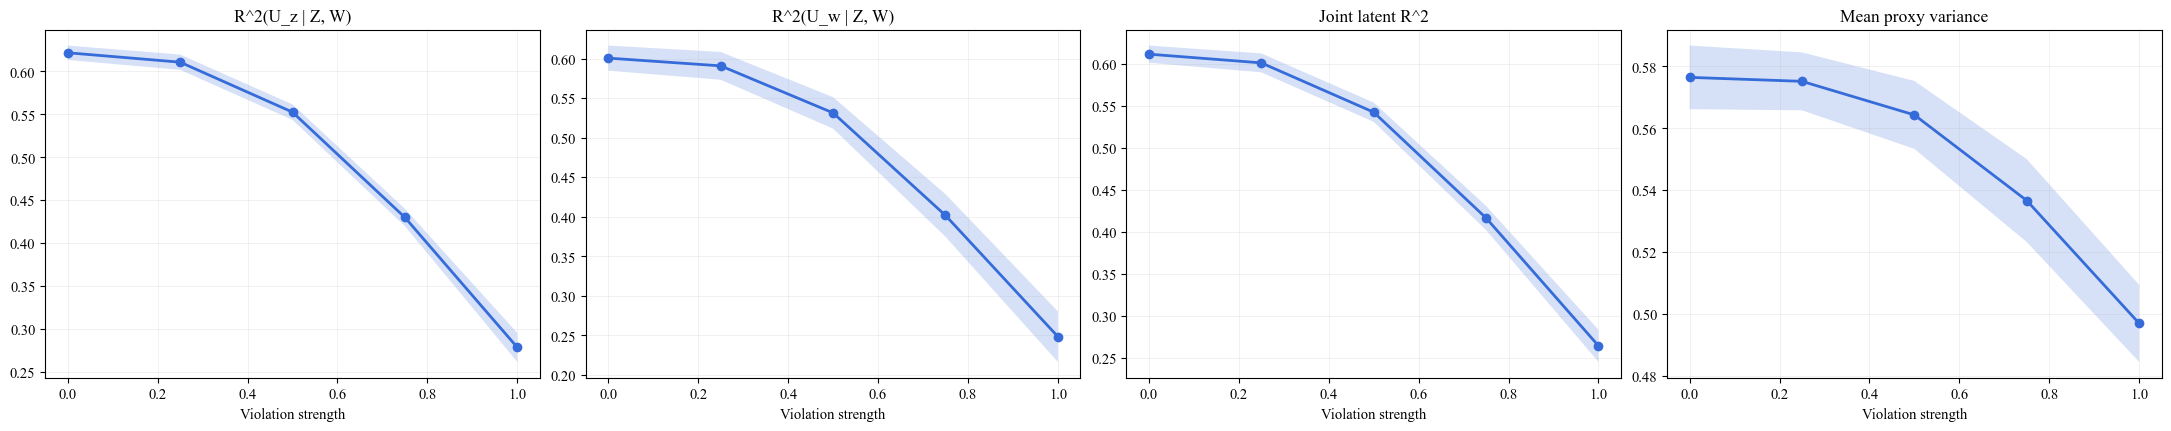

In [18]:
diagnostic_specs = [
    ('latent_uz_r2', 'R^2(U_z | Z, W)'),
    ('latent_uw_r2', 'R^2(U_w | Z, W)'),
    ('joint_latent_r2', 'Joint latent R^2'),
    ('proxy_variance', 'Mean proxy variance'),
]

fig, axes = plt.subplots(1, len(diagnostic_specs), figsize=(21.6, 4.2), constrained_layout=True)
for ax, (metric_key, title) in zip(axes, diagnostic_specs):
    xs, means, ci_low, ci_high = summarize(
        diagnostic_rows,
        'alpha',
        'value',
        filters={'metric': metric_key, 'split': 'test'},
    )
    ax.plot(xs, means, marker='o', linewidth=2)
    ax.fill_between(xs, ci_low, ci_high, alpha=0.2)
    ax.set_title(title)
    ax.set_xlabel('Violation strength')
    ax.grid(alpha=0.25)
plt.show()

## Patient Surface Curves Across Violation Levels

Las celdas siguientes comparan, para varios niveles de violación, las curvas por paciente exportadas por cada run. Se pinta la curva causal oracle, la marginal asociacional `E[Y|X,A]`, la proxy-conditioned y las predicciones del modelo. Si `RELATIVE_TO_GROUND_TRUTH = True`, todas las curvas se muestran restando el ground truth punto a punto.

In [19]:
import json

RUN_MANIFEST = RESULTS_DIR / 'run_manifest.json'
with RUN_MANIFEST.open(encoding='utf-8') as handle:
    run_manifest = json.load(handle)

RELATIVE_TO_GROUND_TRUTH = True
SURFACE_SPLIT = 'test'
SURFACE_SEED = 6
SURFACE_ALPHAS = [float(v) for v in run_manifest['violation_grid'][:3]]
SURFACE_PATIENT_RANKS = [0, 1, 2]
SURFACE_METHODS = [
    method
    for method in METHOD_ORDER
    if method in {row['method'] for row in metrics_rows if row.get('split') == SURFACE_SPLIT}
]

RESULTS_BY_KEY = {}
for row in metrics_rows:
    if row.get('split') != SURFACE_SPLIT:
        continue
    key = (int(row['seed']), float(row['completeness_violation_strength']))
    run_dir = Path(row['run_dir'])
    if not run_dir.is_absolute():
        run_dir = PROJECT_ROOT / run_dir
    RESULTS_BY_KEY.setdefault(key, run_dir)

def load_patient_rows(run_dir: Path):
    with (run_dir / 'patient_curves.csv').open(encoding='utf-8', newline='') as handle:
        curves = list(csv.DictReader(handle))
    with (run_dir / 'patient_metadata.csv').open(encoding='utf-8', newline='') as handle:
        metadata = list(csv.DictReader(handle))
    return curves, metadata

def patient_curve_dict(curve_rows, *, patient_rank: int):
    grouped = defaultdict(list)
    for row in curve_rows:
        if int(row['patient_rank']) != int(patient_rank):
            continue
        method = row['method'].replace('Weighted_', 'Weighted ')
        grouped[(method, row['curve_type'])].append((float(row['treatment']), float(row['value'])))
    out = {}
    for key, pairs in grouped.items():
        pairs = sorted(pairs, key=lambda item: item[0])
        out[key] = (
            np.array([p[0] for p in pairs], dtype=float),
            np.array([p[1] for p in pairs], dtype=float),
        )
    return out

def patient_metadata_lookup(metadata_rows, *, patient_rank: int):
    for row in metadata_rows:
        if int(row['patient_rank']) == int(patient_rank):
            return row
    raise KeyError(f'patient_rank={patient_rank} not found')

def relative_curve(values: np.ndarray, reference: np.ndarray) -> np.ndarray:
    return values - reference if RELATIVE_TO_GROUND_TRUTH else values

run_manifest['surface_patients'], SURFACE_METHODS, SURFACE_ALPHAS

(50,
 ['PMMR', 'Weighted PMMR', 'KPV', 'Weighted KPV', 'DFPV', 'Weighted DFPV'],
 [0.0, 0.25, 0.5])

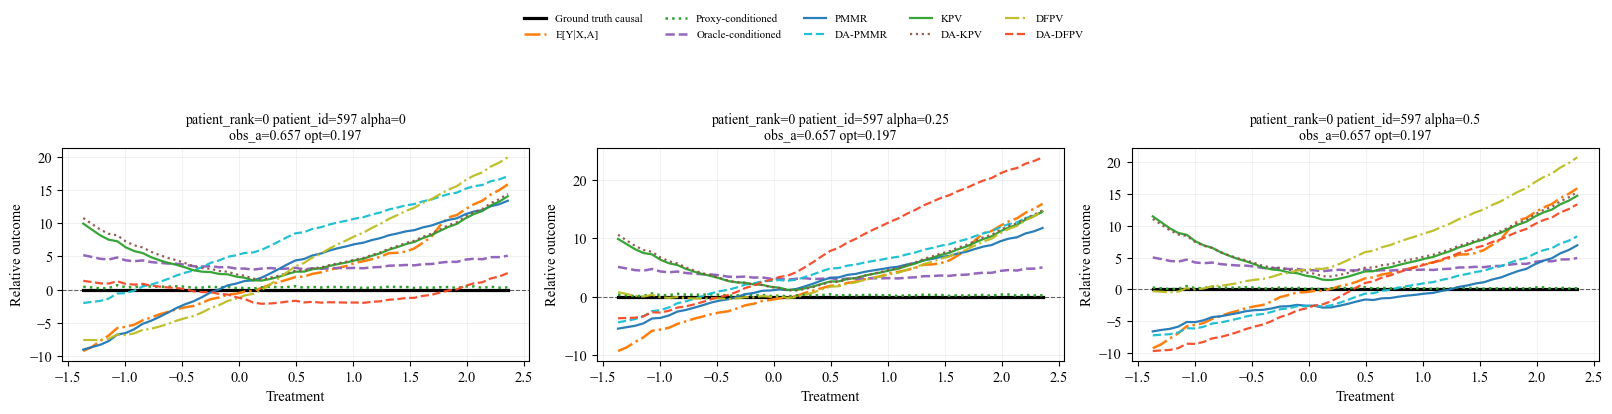

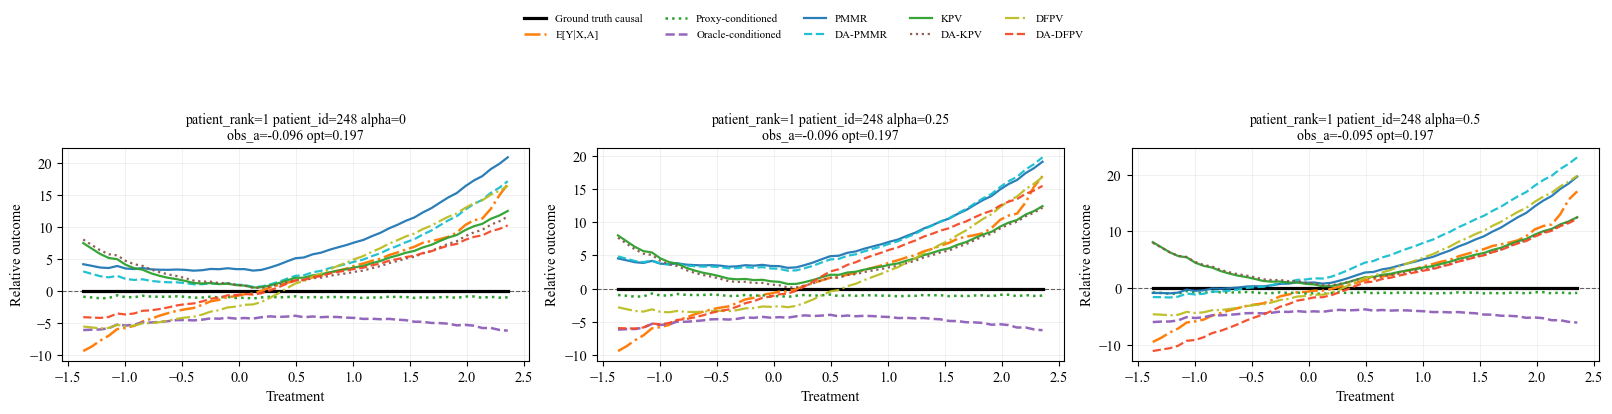

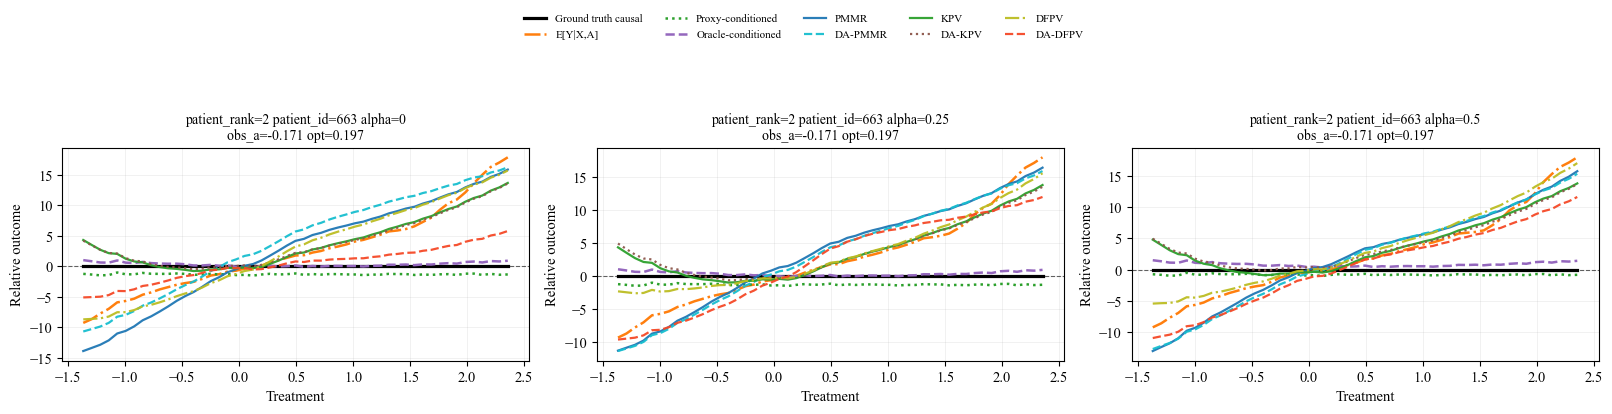

In [20]:
reference_colors = {
    'ground_truth': 'black',
    'associational': '#ff7f0e',
    'proxy_conditioned': '#2ca02c',
    'oracle_conditioned': '#9467bd',
}

GROUND_TRUTH_KEYS = [
    ('reference', 'ground_truth_oracle_conditioned'),
    ('reference', 'ground_truth_causal'),
]

def resolve_ground_truth_curve(curve_map):
    for key in GROUND_TRUTH_KEYS:
        if key in curve_map:
            return curve_map[key]
    raise KeyError(f'Ground-truth curve not found. Available keys: {sorted(curve_map.keys())[:8]} ...')

for patient_rank in SURFACE_PATIENT_RANKS:
    fig, axes = plt.subplots(1, len(SURFACE_ALPHAS), figsize=(5.4 * len(SURFACE_ALPHAS), 4.2))
    axes = np.atleast_1d(axes)
    for ax, alpha in zip(axes, SURFACE_ALPHAS):
        run_dir = RESULTS_BY_KEY[(SURFACE_SEED, float(alpha))]
        curve_rows, metadata_rows = load_patient_rows(run_dir)
        curve_map = patient_curve_dict(curve_rows, patient_rank=patient_rank)
        meta = patient_metadata_lookup(metadata_rows, patient_rank=patient_rank)

        gt_grid, gt_values = resolve_ground_truth_curve(curve_map)
        ax.plot(gt_grid, relative_curve(gt_values, gt_values), color=reference_colors['ground_truth'], linewidth=2.3, label='Ground truth causal')
        if RELATIVE_TO_GROUND_TRUTH:
            ax.axhline(0.0, color='black', linestyle='--', linewidth=0.8, alpha=0.6)

        for ref_curve in ['associational', 'proxy_conditioned', 'oracle_conditioned']:
            ref_key = ('reference', ref_curve)
            if ref_key not in curve_map:
                continue
            ref_grid, ref_values = curve_map[ref_key]
            ax.plot(
                ref_grid,
                relative_curve(ref_values, gt_values),
                color=reference_colors[ref_curve],
                linewidth=1.8,
                linestyle='-.' if ref_curve == 'associational' else (':' if ref_curve == 'proxy_conditioned' else '--'),
                label=(
                    'E[Y|X,A]' if ref_curve == 'associational'
                    else ('Proxy-conditioned' if ref_curve == 'proxy_conditioned' else 'Oracle-conditioned')
                ),
            )

        for method in SURFACE_METHODS:
            pred_key = (method, 'prediction')
            if pred_key not in curve_map:
                continue
            pred_grid, pred_values = curve_map[pred_key]
            ax.plot(pred_grid, relative_curve(pred_values, gt_values), linewidth=1.6, alpha=0.95,
                    color=METHOD_COLORS.get(method, 'tab:blue'),
                    linestyle=METHOD_LINESTYLES.get(method, '-'),
                    label=METHOD_LABELS.get(method, method))

        title = (
            f"patient_rank={patient_rank} patient_id={meta['patient_id']} alpha={alpha:g}\n"
            f"obs_a={float(meta['observed_treatment']):.3f} opt={float(meta['surface_optimal_treatment']):.3f}"
        )
        ax.set_title(title, fontsize=10)
        ax.set_xlabel('Treatment')
        ax.set_ylabel('Relative outcome' if RELATIVE_TO_GROUND_TRUTH else 'Outcome')
        ax.grid(alpha=0.25)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.99),
               ncol=min(len(labels), 5), frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, 0, 1, 0.77))
    plt.show()